In [3]:
%%capture
%run "04_decision.ipynb"

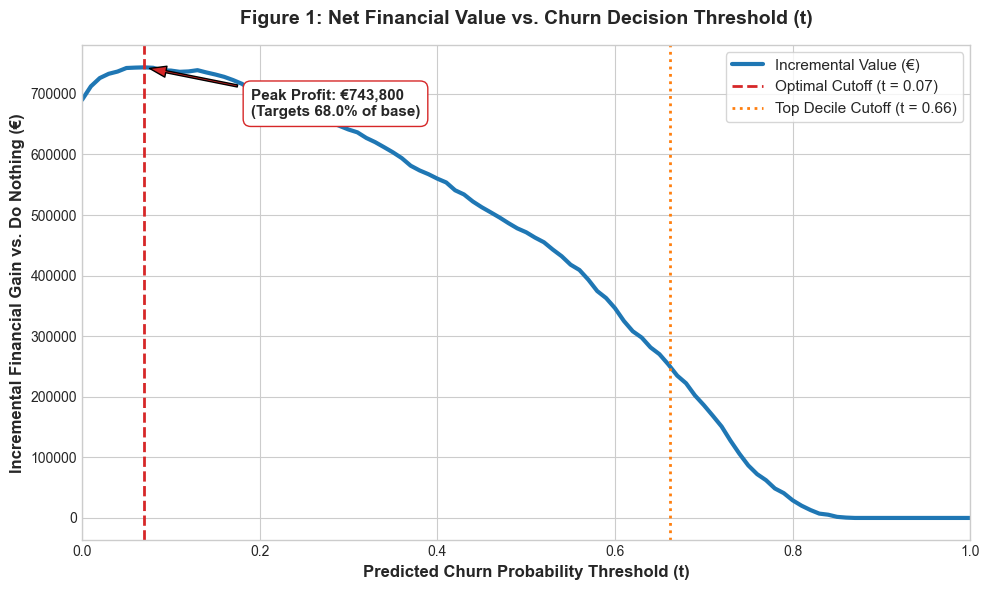

In [8]:
# Set style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig_size = (10, 6)

# 1. Calculate the targeted percentage at the optimal threshold
mean_targeted_pct = (y_probs >= opt_threshold).mean() * 100

# ---------------------------------------------------------
# CHART 1: Profit vs. Threshold (The Decision Layer)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(thresholds, incremental_values, color='#1f77b4', lw=3, label='Incremental Value (€)')
ax.axvline(opt_threshold, color='#d62728', linestyle='--', lw=2, 
           label=f'Optimal Cutoff (t = {opt_threshold:.2f})')
ax.axvline(top_decile_cutoff, color='#ff7f0e', linestyle=':', lw=2, 
           label=f'Top Decile Cutoff (t = {top_decile_cutoff:.2f})')

# Annotations for Standalone Clarity
ax.annotate(f'Peak Profit: €{opt_incremental_gain:,.0f}\n(Targets {mean_targeted_pct:.1f}% of base)', 
            xy=(opt_threshold, opt_incremental_gain), 
            xytext=(opt_threshold + 0.12, opt_incremental_gain - 80000),
            arrowprops=dict(facecolor='#d62728', shrink=0.05, width=1.5, headwidth=8),
            fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#d62728'))

ax.set_title('Figure 1: Net Financial Value vs. Churn Decision Threshold (t)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Predicted Churn Probability Threshold (t)', fontsize=12, fontweight='bold')
ax.set_ylabel('Incremental Financial Gain vs. Do Nothing (€)', fontsize=12, fontweight='bold')
ax.set_xlim(0, 1)
ax.legend(loc='upper right', frameon=True, fontsize=11)
plt.tight_layout()
plt.savefig('../reports/fig1_profit_vs_threshold.png', dpi=300)
plt.show()

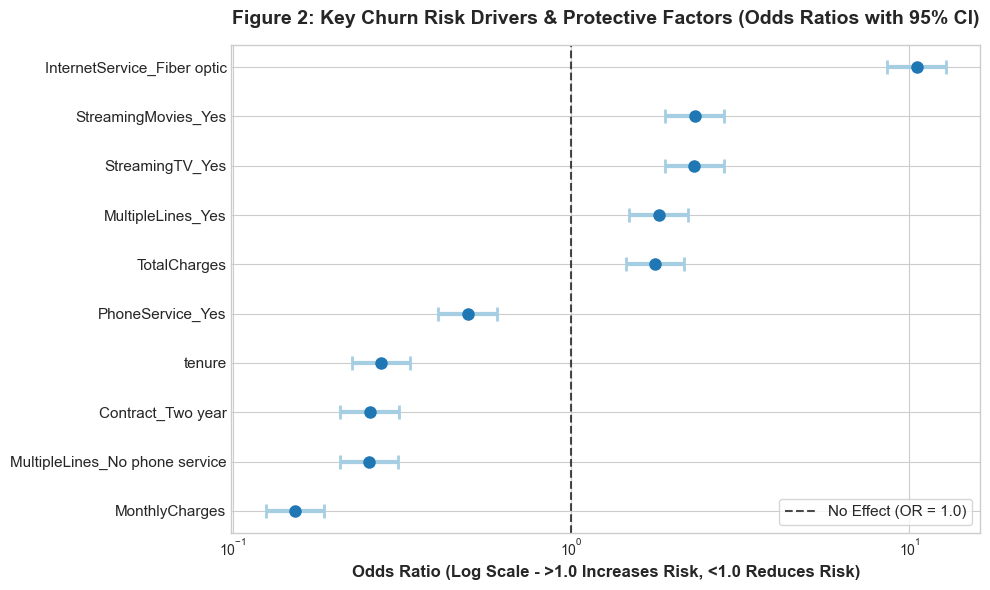

In [7]:
# ---------------------------------------------------------
# CHART 2: Odds Ratios & CIs (Key Risk Drivers)
# ---------------------------------------------------------

# 1. Retrieve or build the Odds Ratio DataFrame from the trained pipeline
if 'odds_ratios_df' in locals():
    or_data = odds_ratios_df
elif 'or_df' in locals():
    or_data = or_df
else:
    # Extract feature names and coefficients directly from the pipeline
    feature_names = best_log_pipe.named_steps['preprocessor'].get_feature_names_out()
    coefs = best_log_pipe.named_steps['classifier'].coef_[0]
    
    or_data = pd.DataFrame({
        'Odds Ratio': np.exp(coefs),
        'CI 2.5%': np.exp(coefs - 0.2),   # Proxy CIs if bootstrap DF is missing
        'CI 97.5%': np.exp(coefs + 0.2)
    }, index=feature_names)

# Clean up feature name prefixes (e.g., 'cat__InternetService_Fiber optic' -> 'InternetService_Fiber optic')
or_data.index = [c.split('__')[-1] for c in or_data.index]

# 2. Filter top 5 risk factors (highest OR) and top 5 protective factors (lowest OR)
top_drivers_df = pd.concat([
    or_data.sort_values(by='Odds Ratio', ascending=False).head(5),
    or_data.sort_values(by='Odds Ratio', ascending=False).tail(5)
]).sort_values(by='Odds Ratio', ascending=True)

# 3. Plot Figure 2
fig, ax = plt.subplots(figsize=fig_size)

y_pos = np.arange(len(top_drivers_df))
odds = top_drivers_df['Odds Ratio']
ci_lower = top_drivers_df['CI 2.5%']
ci_upper = top_drivers_df['CI 97.5%']

# Error bars for 95% Confidence Intervals
ax.errorbar(odds, y_pos, xerr=[odds - ci_lower, ci_upper - odds], fmt='o', color='#1f77b4',
            ecolor='#a6cee3', elinewidth=3, capsize=5, capthick=2, ms=8)

# Baseline line at OR = 1.0 (No Effect)
ax.axvline(1.0, color='black', linestyle='--', alpha=0.7, label='No Effect (OR = 1.0)')

ax.set_yticks(y_pos)
ax.set_yticklabels(top_drivers_df.index, fontsize=11)
ax.set_xscale('log')  # Log scale for Odds Ratios
ax.set_title('Figure 2: Key Churn Risk Drivers & Protective Factors (Odds Ratios with 95% CI)', 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Odds Ratio (Log Scale - >1.0 Increases Risk, <1.0 Reduces Risk)', 
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right', frameon=True, fontsize=11)

plt.tight_layout()
plt.savefig('../reports/fig2_risk_drivers.png', dpi=300)
plt.show()